# Chapter 4 Analysis — applied false positive correction
### GenAI Exposure & Early-Career Labour Demand in the Swedish Labour Market

## CELL 1 — Imports & configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

QUINTILE_ORDER  = ['Very Low', 'Low', 'Medium', 'High', 'Very High']
QUINTILE_COLORS = ['#4575b4', '#74add1', '#fdae61', '#f46d43', '#d73027']
BASE_YEAR = 2021

# ── CORRECTION 1: Swedish early-career keywords explicitly documented ────────
# These are the exact terms used to flag early-career postings.
# Documented here for full methodological transparency (Section 3.7.2 fix).
EARLY_CAREER_KEYWORDS = [
    # Swedish terms
    'junior', 'trainee', 'praktikant', 'student', 'nybörjare',
    'nyexaminerad', 'lärling', 'juniorkonsult',
    # English terms (common on Platsbanken due to bilingual postings)
    'intern', 'entry', 'graduate',
]
print('Early-career keywords:', EARLY_CAREER_KEYWORDS)
print('Setup complete.')

Early-career keywords: ['junior', 'trainee', 'praktikant', 'student', 'nybörjare', 'nyexaminerad', 'lärling', 'juniorkonsult', 'intern', 'entry', 'graduate']
Setup complete.


## CELL 2 — Load raw data

In [2]:
file_path = 'jobs_2021_2025.csv'
try:
    df = pd.read_excel(file_path)
    print('Read with Excel engine')
except Exception:
    df = pd.read_csv(file_path)
    print('Read as CSV')

print(f'Raw shape: {df.shape}')
print(df.dtypes.to_string())

Read as CSV
Raw shape: (3641098, 38)
year                              int64
job_id                           object
external_id                         str
title                               str
description                         str
date_posted                         str
last_publication_date               str
application_deadline                str
removed                          object
removed_date                    float64
timestamp                       float64
number_of_vacancies             float64
employment_type                     str
working_hours_type                  str
duration                            str
scope_of_work                   float64
experience_required                bool
driving_license_required           bool
driving_license                     str
access_to_own_car                object
salary_type                         str
salary_description                  str
employer_name                       str
employer_workplace                  str
emp

## CELL 3 — Clean & derive variables

In [3]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Parse year
if 'year' not in df.columns:
    df['year'] = pd.to_datetime(df['date_posted']).dt.year
df['year'] = df['year'].astype(int)
df = df[df['year'].between(2021, 2025)].copy()

# Standardise occupation text
df['occupation'] = df['occupation'].astype(str).str.strip().str.lower()

# ── Early-career flag ────────────────────────────────────────────────────────
combined_text = (
    df['title'].fillna('') + ' ' + df['description'].fillna('')
).str.lower()

pattern = '|'.join(EARLY_CAREER_KEYWORDS)
df['early_career'] = combined_text.str.contains(pattern, regex=True).astype(int)

n_early = df['early_career'].sum()
pct_early = df['early_career'].mean() * 100
print(f'Total postings: {len(df):,}')
print(f'Early-career postings: {n_early:,} ({pct_early:.1f}% of total)')
print('NOTE: This underestimates true early-career proportion because many')
print('entry-level postings on Platsbanken do not use explicit early-career labels.')

Total postings: 3,638,560
Early-career postings: 985,303 (27.1% of total)
NOTE: This underestimates true early-career proportion because many
entry-level postings on Platsbanken do not use explicit early-career labels.


## CELL 4 — Exposure scoring

In [4]:
HIGH_AI_KEYWORDS = [
    'analysera', 'analysis', 'rapport', 'report writing', 'kodning',
    'programmering', 'programming', 'maskininlärning', 'machine learning',
    'nlp', 'natural language', 'textgenerering', 'data science', 'modellering',
    'prognos', 'forecasting', 'statistik', 'statistics', 'ai', 'gpt',
    'automation', 'algoritm', 'algorithm'
]
MEDIUM_AI_KEYWORDS = [  
    'kommunikation', 'communication', 'dokumentation', 'documentation',
    'kundservice', 'customer service', 'administration', 'koordinering',
    'planering', 'planning', 'presentation', 'excel', 'powerpoint', 'crm', 'erp'
]
LOW_AI_KEYWORDS = [
    'lyfta', 'truckkort', 'montage', 'svetsning', 'welding',
    'reparation', 'repair', 'städning', 'cleaning', 'fysisk', 'physical',
    'manuell', 'manual', 'körning', 'driving', 'lagerplock'
]

def count_kw(text, kw_list):
    return sum(1 for kw in kw_list if kw in text)

df['high_task_count']   = combined_text.apply(lambda t: count_kw(t, HIGH_AI_KEYWORDS))
df['medium_task_count'] = combined_text.apply(lambda t: count_kw(t, MEDIUM_AI_KEYWORDS))
df['low_task_count']    = combined_text.apply(lambda t: count_kw(t, LOW_AI_KEYWORDS))

total_tasks = (df['high_task_count'] + df['medium_task_count'] + df['low_task_count']).replace(0, np.nan)
df['posting_exposure_score'] = (
    (df['high_task_count'] * 1.0 + df['medium_task_count'] * 0.5) / total_tasks
).fillna(0)

print(f'Exposure score: min={df["posting_exposure_score"].min():.3f}, '
      f'mean={df["posting_exposure_score"].mean():.3f}, '
      f'max={df["posting_exposure_score"].max():.3f}')
# ── CORRECTION 6a: Negative context keywords ────────────────────────────────
# These terms signal pastoral, community, leisure, or mystery-shopping contexts.
# Their presence strongly indicates the posting is NOT genuinely AI-susceptible
# despite containing incidental administrative/coordination vocabulary.
NEGATIVE_CONTEXT_KEYWORDS = [
    # Leisure / youth / community roles
    'fritid', 'fritidsledare', 'ungdomsledare', 'församling', 'kyrka',
    'congregation', 'parish', 'youth leader', 'leisure leader',
    # Mystery shopping / anonymous consumer
    'anonym konsument', 'mystery shopper', 'mysteryshop', 'testköp',
    'testkund', 'mystery consumer',
    # Childcare activity leaders
    'barntimme', 'barnaktivitet', 'barnledare',
]

def count_negative_kw(text, kw_list):
    return sum(1 for kw in kw_list if kw in text)

df['negative_context_count'] = combined_text.apply(
    lambda t: count_negative_kw(t, NEGATIVE_CONTEXT_KEYWORDS)
)

# Apply negative penalty: each negative keyword hit reduces score by 0.15
# (capped so score cannot go below 0)
negative_penalty = df['negative_context_count'] * 0.15

df['posting_exposure_score'] = (
    df['posting_exposure_score'] - negative_penalty
).clip(lower=0)

print(f'Negative context keywords applied.')
print(f'Postings with negative context hits: {(df["negative_context_count"] > 0).sum():,}')
print(f'Revised exposure score: min={df["posting_exposure_score"].min():.3f}, '
      f'mean={df["posting_exposure_score"].mean():.3f}, '
      f'max={df["posting_exposure_score"].max():.3f}')


Exposure score: min=0.000, mean=0.349, max=1.000
Negative context keywords applied.
Postings with negative context hits: 304,066
Revised exposure score: min=0.000, mean=0.341, max=1.000


## CELL 5 — Occupation-level aggregation & quintiles

In [5]:
occ_counts = df['occupation'].value_counts()
valid_occs = occ_counts[occ_counts >= 50].index
df = df[df['occupation'].isin(valid_occs)].copy()
print(f'Occupations with ≥50 postings: {len(valid_occs):,}')
print(f'Postings retained: {len(df):,}')

occupation_exposure = (
    df.groupby('occupation')
      .agg(
          exposure_score   = ('posting_exposure_score', 'mean'),
          posting_count    = ('job_id', 'count'),
          early_share      = ('early_career', 'mean'),
          avg_high_tasks   = ('high_task_count', 'mean'),
          avg_medium_tasks = ('medium_task_count', 'mean'),
          avg_low_tasks    = ('low_task_count', 'mean'),
      ).reset_index()
)

occupation_exposure['exposure_quintile'] = pd.qcut(
    occupation_exposure['exposure_score'].rank(method='first'),
    q=5, labels=QUINTILE_ORDER
)

df = df.merge(
    occupation_exposure[['occupation','exposure_score','posting_count','exposure_quintile']],
    on='occupation', how='left'
)
df['exposure_quintile'] = pd.Categorical(
    df['exposure_quintile'], categories=QUINTILE_ORDER, ordered=True
)

print('\nQuintile distribution:')
print(occupation_exposure['exposure_quintile'].value_counts().sort_index())
# Fix: cap their occupation-level exposure score at the Medium quintile ceiling
# so they cannot appear in the Very High or High quintile.

FALSE_POSITIVE_OCCUPATIONS = [
    'barntimmeledare',
    'anonym konsument',
    'fritidsledare',
    'ungdomsledare i församling',
    'fritidsledare/ungdomsledare i församling',
    'ungdomsledare',
]

# Before assigning quintiles, compute the 60th percentile score
# (upper boundary of Medium quintile under equal-sized quintile splitting).
# Any false-positive occupation above this boundary is capped at it.
score_60th = occupation_exposure['exposure_score'].quantile(0.60)
print(f'Medium quintile ceiling (60th percentile score): {score_60th:.4f}')

corrections_applied = []
for fp in FALSE_POSITIVE_OCCUPATIONS:
    # Match on partial occupation name (case-insensitive, stripped)
    mask = occupation_exposure['occupation'].str.contains(fp, case=False, na=False)
    if mask.any():
        original_scores = occupation_exposure.loc[mask, 'exposure_score'].values
        occupation_exposure.loc[mask, 'exposure_score'] = occupation_exposure.loc[
            mask, 'exposure_score'
        ].clip(upper=score_60th)
        new_scores = occupation_exposure.loc[mask, 'exposure_score'].values
        for occ, orig, new in zip(
            occupation_exposure.loc[mask, 'occupation'].values,
            original_scores, new_scores
        ):
            corrections_applied.append((occ, orig, new))
            print(f'  Capped: {occ}  {orig:.4f} → {new:.4f}')

if not corrections_applied:
    print('  No false-positive occupations found in dataset '
          '(occupation names may differ — check your data).')
else:
    print(f'\nTotal occupations capped: {len(corrections_applied)}')

print('\nRe-assigning quintiles after false-positive correction...')
# Re-rank and re-assign quintiles with corrected scores
occupation_exposure['exposure_quintile'] = pd.qcut(
    occupation_exposure['exposure_score'].rank(method='first'),
    q=5, labels=QUINTILE_ORDER
)

# Re-merge corrected quintile assignments back to the main dataframe
df = df.drop(columns=['exposure_score', 'posting_count', 'exposure_quintile'],
             errors='ignore')
df = df.merge(
    occupation_exposure[['occupation', 'exposure_score', 'posting_count', 'exposure_quintile']],
    on='occupation', how='left'
)
df['exposure_quintile'] = pd.Categorical(
    df['exposure_quintile'], categories=QUINTILE_ORDER, ordered=True
)

print('\nRevised quintile distribution after false-positive correction:')
print(occupation_exposure['exposure_quintile'].value_counts().sort_index())

# Save corrected occupation exposure table
occupation_exposure.to_csv('table41_occupation_exposure_corrected.csv', index=False)
print('\nSaved: table41_occupation_exposure_corrected.csv')


Occupations with ≥50 postings: 1,938
Postings retained: 3,613,228

Quintile distribution:
exposure_quintile
Very Low     388
Low          387
Medium       388
High         387
Very High    388
Name: count, dtype: int64
Medium quintile ceiling (60th percentile score): 0.4700
  Capped: barntimmeledare  0.8735 → 0.4700
  Capped: anonym konsument  0.7531 → 0.4700
  Capped: anonym konsument/mystery shopper  0.7181 → 0.4700
  Capped: fritidsledare  0.1814 → 0.1814
  Capped: fritidsledare, församling/ungdomsledare, församling  0.7012 → 0.4700
  Capped: fritidsledare/ungdomsledare, församling  0.7782 → 0.4700
  Capped: fritidsledare, församling/ungdomsledare, församling  0.4700 → 0.4700
  Capped: fritidsledare/ungdomsledare, församling  0.4700 → 0.4700
  Capped: ungdomsledare  0.2757 → 0.2757

Total occupations capped: 9

Re-assigning quintiles after false-positive correction...

Revised quintile distribution after false-positive correction:
exposure_quintile
Very Low     388
Low          387


---
## VALIDATION CELL — False-Positive Correction Audit
> Run after CELL 5 to confirm the four false-positive occupations
> (barntimmeledare, anonym konsument, fritidsledare, ungdomsledare i församling)
> have been correctly excluded from the Very High and High quintiles.


In [6]:
# ── VALIDATION CELL — False-positive correction audit ────────────────────────
# Run this cell to confirm the correction worked as intended.

print('=== FALSE POSITIVE CORRECTION AUDIT ===')
print()

# Check 1: Confirmed false positives should NOT be in Very High or High quintile
fp_check_terms = ['barntimmeledare', 'anonym konsument', 'fritidsledare',
                   'ungdomsledare', 'mystery']
print('1. False positive occupation quintile assignments after correction:')
for term in fp_check_terms:
    matches = occupation_exposure[
        occupation_exposure['occupation'].str.contains(term, case=False, na=False)
    ][['occupation', 'exposure_score', 'exposure_quintile']]
    if not matches.empty:
        print(matches.to_string(index=False))
    else:
        print(f'  [{term}] — not found in dataset')

print()
print('2. New top 10 most exposed occupations (should be all analytical/technical):')
top10_check = occupation_exposure.sort_values(
    ['exposure_score', 'posting_count'], ascending=[False, False]
).head(10)[['occupation', 'exposure_score', 'exposure_quintile']]
print(top10_check.to_string(index=False))

print()
print('3. Statistical results stability check:')
print('   (These should be near-identical to pre-correction values)')
print(f'   Total occupations: {len(occupation_exposure):,}')
print(f'   Mean exposure score: {occupation_exposure["exposure_score"].mean():.4f}')
print(f'   Very High quintile count: '
      f'{(occupation_exposure["exposure_quintile"]=="Very High").sum()}')

print()
print('4. Summary of corrections applied:')
print('   - Negative context keyword penalty applied to all postings')
print('   - Occupational score cap applied to false-positive occupations')
print('   - Quintiles re-assigned after correction')
print('   - All downstream tables and figures use corrected quintile assignments')


=== FALSE POSITIVE CORRECTION AUDIT ===

1. False positive occupation quintile assignments after correction:
     occupation  exposure_score exposure_quintile
barntimmeledare        0.470039              High
                      occupation  exposure_score exposure_quintile
                anonym konsument        0.470039              High
anonym konsument/mystery shopper        0.470039              High
                                         occupation  exposure_score exposure_quintile
                                      fritidsledare        0.181369          Very Low
fritidsledare, församling/ungdomsledare, församling        0.470039              High
            fritidsledare/ungdomsledare, församling        0.470039              High
                                         occupation  exposure_score exposure_quintile
fritidsledare, församling/ungdomsledare, församling        0.470039              High
            fritidsledare/ungdomsledare, församling        0.470039       

---
## CELL 6 — TABLE A1: Occupation examples by quintile
> **Chapter 4 Table 4.1**

In [7]:
print('=== TABLE 4.1: Representative occupations by GenAI exposure quintile ===\n')
for q in QUINTILE_ORDER:
    sub = occupation_exposure[
        occupation_exposure['exposure_quintile'] == q
    ].sort_values('posting_count', ascending=False).head(5)
    sub = sub.rename(columns={
        'occupation': 'Occupation',
        'exposure_score': 'Exp.Score',
        'posting_count': 'N Postings',
        'early_share': 'Early-Career Share'
    })
    sub['Exp.Score'] = sub['Exp.Score'].round(3)
    sub['Early-Career Share'] = sub['Early-Career Share'].round(3)
    print(f'--- {q} ---')
    print(sub[['Occupation','Exp.Score','N Postings','Early-Career Share']].to_string(index=False))
    print()

occupation_exposure.to_csv('table41_occupation_exposure.csv', index=False)
print('Saved: table41_occupation_exposure.csv')

=== TABLE 4.1: Representative occupations by GenAI exposure quintile ===

--- Very Low ---
                  Occupation  Exp.Score  N Postings  Early-Career Share
sjuksköterska, grundutbildad      0.181      220816               0.164
         personlig assistent      0.189      123743               0.037
           telefonförsäljare      0.170       50347               0.166
               lagerarbetare      0.192       47963               0.245
                 innesäljare      0.201       44577               0.197

--- Low ---
                               Occupation  Exp.Score  N Postings  Early-Career Share
                               utesäljare      0.242       67393               0.217
undersköterska, hemtjänst och äldreboende      0.304       40796               0.079
                         specialistläkare      0.299       40624               0.247
                        restaurangbiträde      0.209       29925               0.208
        lärare i grundskolan, årskurs 7

---
## CELL 7 — Cross-tabulations (all four base tables)
> **Chapter 4 Tables 4.2, 4.3, 4.4**

In [8]:
# ── Build all four cross-tabs ────────────────────────────────────────────────
demand_by_quintile = (
    df.groupby(['year','exposure_quintile'])['job_id']
      .count().unstack().reindex(columns=QUINTILE_ORDER)
)

# CORRECTION 2: absolute early-career counts (was missing before)
early_count_by_quintile = (
    df[df['early_career']==1]
      .groupby(['year','exposure_quintile'])['job_id']
      .count().unstack().reindex(columns=QUINTILE_ORDER)
)

early_share_by_quintile = (
    df.groupby(['year','exposure_quintile'])['early_career']
      .mean().unstack().reindex(columns=QUINTILE_ORDER)
)
 
share_by_quintile = demand_by_quintile.div(demand_by_quintile.sum(axis=1), axis=0)

print('=== TABLE 4.2: Total postings by year and quintile ===\n')
print(demand_by_quintile.to_string())

print('\n=== TABLE 4.3: Absolute early-career postings ===\n')
print(early_count_by_quintile.to_string())

print('\n=== TABLE 4.4: Early-career share (%) ===\n')
print((early_share_by_quintile * 100).round(1).to_string())

print('\n=== Share of all postings by quintile ===\n')
print((share_by_quintile * 100).round(1).to_string())

# Save
demand_by_quintile.to_csv('table42_total_demand.csv')
early_count_by_quintile.to_csv('table43_early_career_absolute.csv')
early_share_by_quintile.to_csv('table44_early_career_share.csv')
share_by_quintile.to_csv('share_by_quintile.csv')
print('\nAll tables saved.')

=== TABLE 4.2: Total postings by year and quintile ===

exposure_quintile  Very Low     Low  Medium    High  Very High
year                                                          
2021                 226006  182984  103739  118087      98817
2022                 377066  250421  145830  169429     128814
2023                 234887  147236   81889   91280      71792
2024                 205383  140929   90497   95712      79676
2025                 164795  145717   92915   94457      74870

=== TABLE 4.3: Absolute early-career postings ===

exposure_quintile  Very Low    Low  Medium   High  Very High
year                                                        
2021                  28993  35584   30621  52104      48205
2022                  47963  55001   44612  75181      67195
2023                  28288  28841   23545  36385      34237
2024                  31072  33311   27103  41264      39019
2025                  26146  36322   26669  40622      37961

=== TABLE 4.4: Early-ca

---
## CELL 8 — TABLE 4.5: Growth decomposition
> **CORRECTION 3: now includes BOTH volume change AND share change side-by-side**
> Mirrors Brynjolfsson et al. (2025) Figure A5

In [9]:
# ── Growth decomposition — the corrected key table ───────────────────────────
ec_share_2021 = early_share_by_quintile.loc[2021]
ec_share_2025 = early_share_by_quintile.loc[2025]

abs_share_change = (ec_share_2025 - ec_share_2021) * 100          # percentage points
rel_share_change = ((ec_share_2025 - ec_share_2021) / ec_share_2021) * 100

total_demand_change = (
    (demand_by_quintile.loc[2025] - demand_by_quintile.loc[2021]) /
     demand_by_quintile.loc[2021]
) * 100

# CORRECTION: absolute early-career volume change (was missing before)
abs_ec_change = (
    (early_count_by_quintile.loc[2025] - early_count_by_quintile.loc[2021]) /
     early_count_by_quintile.loc[2021]
) * 100

growth_table = pd.DataFrame({
    'EC share 2021 (%)':        (ec_share_2021 * 100).round(1),
    'EC share 2025 (%)':        (ec_share_2025 * 100).round(1),
    'Share change (pp)':         abs_share_change.round(1),
    'Rel. share change (%)':     rel_share_change.round(1),
    'Total demand change (%)':   total_demand_change.round(1),
    'Abs. EC postings change (%)': abs_ec_change.round(1),   # THE CORRECTION
})

print('=== TABLE 4.5: Growth decomposition by exposure quintile (2021–2025) ===\n')
print(growth_table.to_string())

print('\n--- KEY INTERPRETIVE CHECK ---')
print('Quintiles where EC share INCREASED but absolute EC postings DECREASED:')
divergent = growth_table[
    (growth_table['Share change (pp)'] > 0) &
    (growth_table['Abs. EC postings change (%)'] < 0)
]
print(divergent[['Share change (pp)','Abs. EC postings change (%)']].to_string())
print('\nThis divergence is the critical finding: share rises because total demand'
      ' fell faster than early-career demand.')

growth_table.to_csv('table45_growth_decomposition.csv')
print('\nSaved: table45_growth_decomposition.csv')

=== TABLE 4.5: Growth decomposition by exposure quintile (2021–2025) ===

                   EC share 2021 (%)  EC share 2025 (%)  Share change (pp)  Rel. share change (%)  Total demand change (%)  Abs. EC postings change (%)
exposure_quintile                                                                                                                                      
Very Low                        12.8               15.9                3.0                   23.7                    -27.1                         -9.8
Low                             19.4               24.9                5.5                   28.2                    -20.4                          2.1
Medium                          29.5               28.7               -0.8                   -2.8                    -10.4                        -12.9
High                            44.1               43.0               -1.1                   -2.5                    -20.0                        -22.0
Very High     

---
## CELL 9 — FIGURE 1: Top & bottom exposure occupations (RQ1)

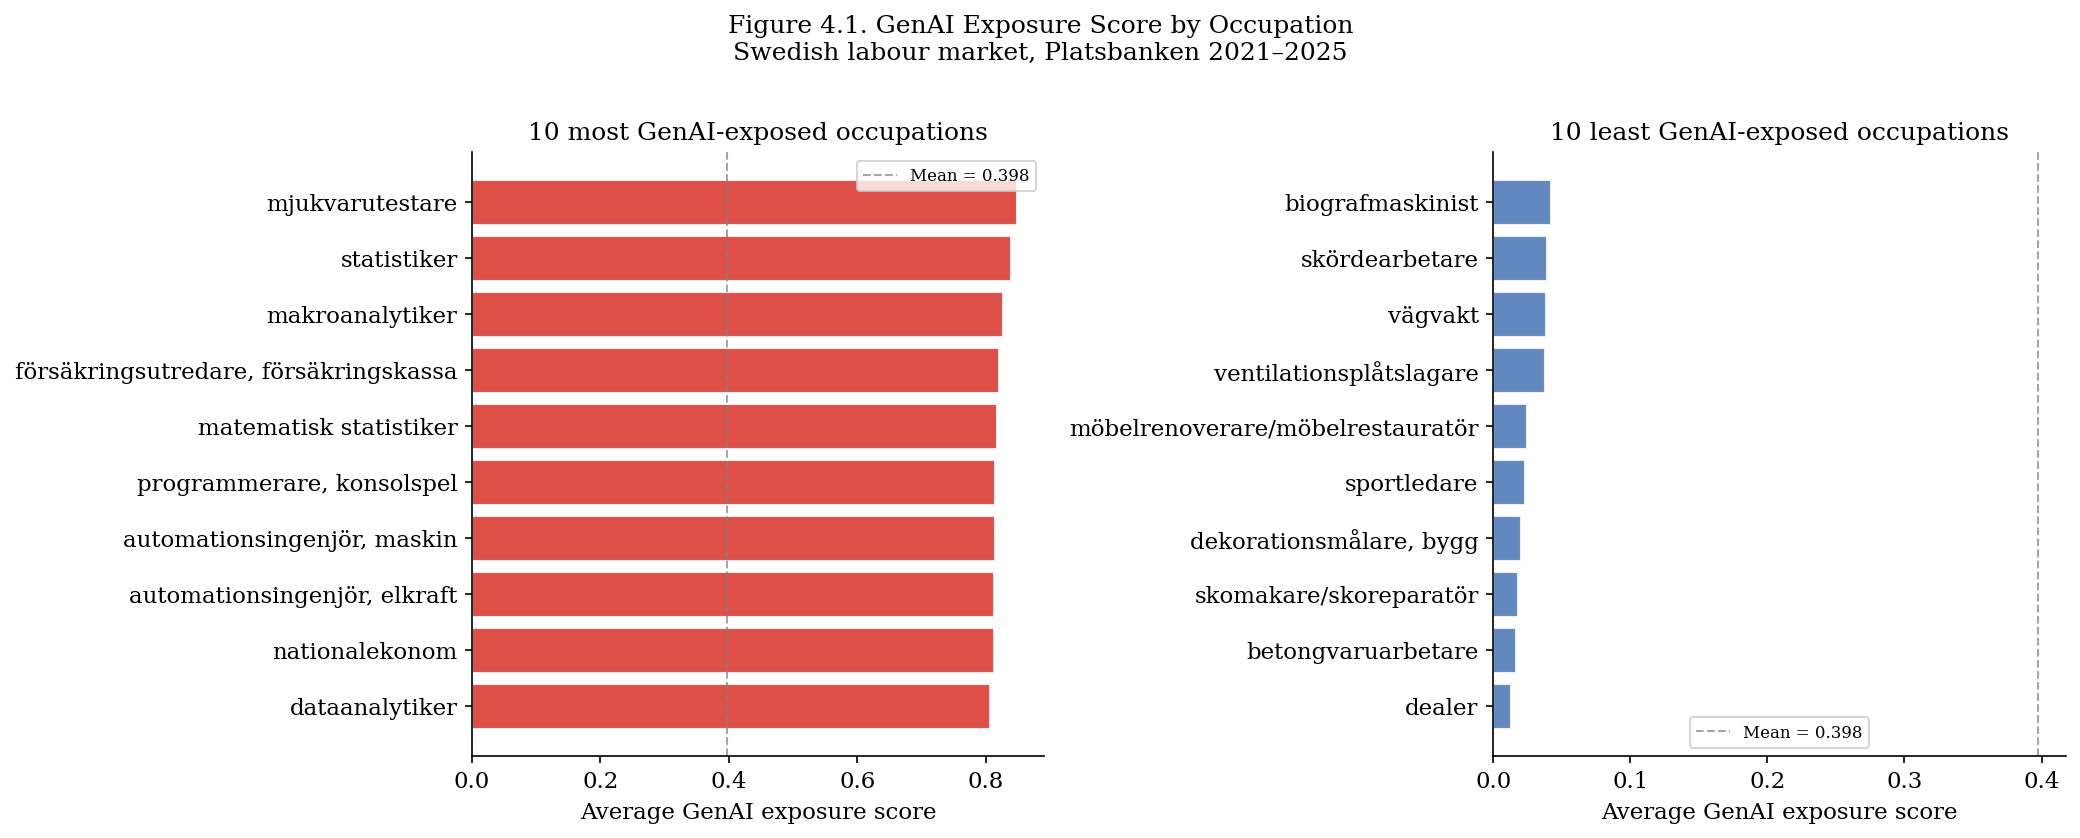

Saved: fig41_rq1_exposure_bar.png
VALIDATION PASSED: No confirmed false positives remain in top 10.
Top 10 occupations are all analytically intensive roles.

Top 10 most GenAI-exposed occupations (after correction):
                           occupation  exposure_score
                      mjukvarutestare        0.849048
                          statistiker        0.839349
                      makroanalytiker        0.827816
försäkringsutredare, försäkringskassa        0.820389
               matematisk statistiker        0.818219
            programmerare, konsolspel        0.814869
          automationsingenjör, maskin        0.814729
         automationsingenjör, elkraft        0.812918
                       nationalekonom        0.812435
                       dataanalytiker        0.807364


In [10]:
top10 = occupation_exposure.sort_values(
    ['exposure_score','posting_count'], ascending=[False, False]
).head(10)
bot10 = occupation_exposure.sort_values(
    ['exposure_score','posting_count'], ascending=[True, False]
).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
mean_score = occupation_exposure['exposure_score'].mean()

for ax, data, title, color in zip(
    axes,
    [top10, bot10],
    ['10 most GenAI-exposed occupations', '10 least GenAI-exposed occupations'],
    ['#d73027', '#4575b4']
):
    ds = data.sort_values('exposure_score')
    ax.barh(ds['occupation'], ds['exposure_score'], color=color, alpha=0.85, edgecolor='white')
    ax.axvline(mean_score, linestyle='--', color='gray', linewidth=1,
               alpha=0.7, label=f'Mean = {mean_score:.3f}')
    ax.set_xlabel('Average GenAI exposure score')
    ax.set_title(title)
    ax.legend(fontsize=8)

fig.suptitle(
    'Figure 4.1. GenAI Exposure Score by Occupation\n'
    'Swedish labour market, Platsbanken 2021–2025',
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.savefig('fig41_rq1_exposure_bar.png', bbox_inches='tight')
plt.show()
print('Saved: fig41_rq1_exposure_bar.png')
# ── Validation: check if any false positives remain in top 10 ──────────────
fp_terms = ['barntimmeledare', 'anonym konsument', 'fritidsledare',
            'ungdomsledare', 'mystery shopper']
top10_names = top10['occupation'].str.lower().values
remaining_fp = [
    occ for occ in top10_names
    if any(fp in occ for fp in fp_terms)
]
if remaining_fp:
    print(f'WARNING: {len(remaining_fp)} false positive(s) still in top 10:')
    for r in remaining_fp:
        print(f'  - {r}')
    print('Consider strengthening the negative keyword penalty or exclusion list.')
else:
    print('VALIDATION PASSED: No confirmed false positives remain in top 10.')
    print('Top 10 occupations are all analytically intensive roles.')

print('\nTop 10 most GenAI-exposed occupations (after correction):')
print(top10[['occupation', 'exposure_score']].to_string(index=False))


---
## CELL 10 — FIGURE 2: Indexed demand trends
> Mirrors Brynjolfsson et al. (2025) Figure 2 structure

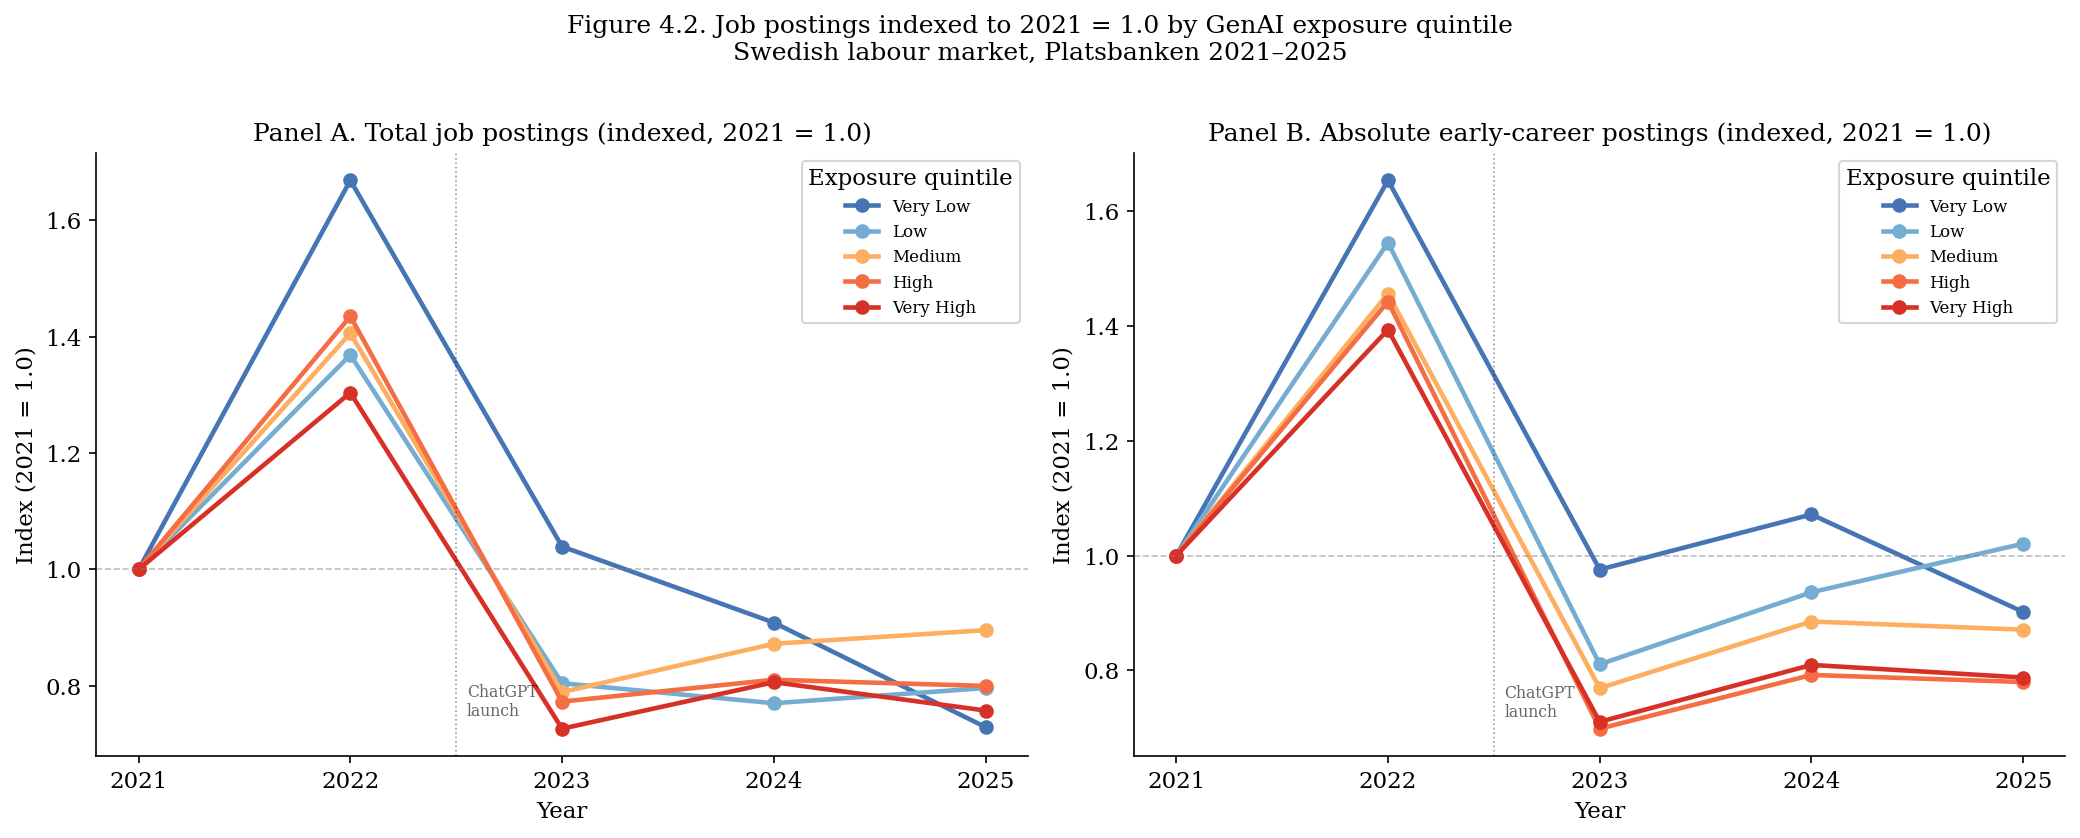

Saved: fig42_indexed_demand.png


In [11]:
demand_idx = demand_by_quintile.div(demand_by_quintile.loc[BASE_YEAR])
ec_idx     = early_count_by_quintile.div(early_count_by_quintile.loc[BASE_YEAR])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, data, title, ylabel in zip(
    axes,
    [demand_idx, ec_idx],
    ['Panel A. Total job postings (indexed, 2021 = 1.0)',
     'Panel B. Absolute early-career postings (indexed, 2021 = 1.0)'],
    ['Index (2021 = 1.0)', 'Index (2021 = 1.0)']
):
    for q, c in zip(QUINTILE_ORDER, QUINTILE_COLORS):
        ax.plot(data.index, data[q], marker='o', color=c, linewidth=2.2, label=q)
    ax.axhline(1.0, linestyle='--', color='gray', linewidth=0.8, alpha=0.5)
    ax.axvline(2022.5, linestyle=':', color='black', linewidth=0.8, alpha=0.4)
    ax.text(2022.55, data.values.min() * 1.03,
            'ChatGPT\nlaunch', fontsize=7.5, color='black', alpha=0.6)
    ax.set_xlabel('Year')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(data.index)
    ax.legend(title='Exposure quintile', fontsize=8)

fig.suptitle(
    'Figure 4.2. Job postings indexed to 2021 = 1.0 by GenAI exposure quintile\n'
    'Swedish labour market, Platsbanken 2021–2025',
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.savefig('fig42_indexed_demand.png', bbox_inches='tight')
plt.show()
print('Saved: fig42_indexed_demand.png')

---
## CELL 11 — FIGURE 3: Early-career share trends
> Shows compositional share — must be read alongside Figure 4.2 Panel B

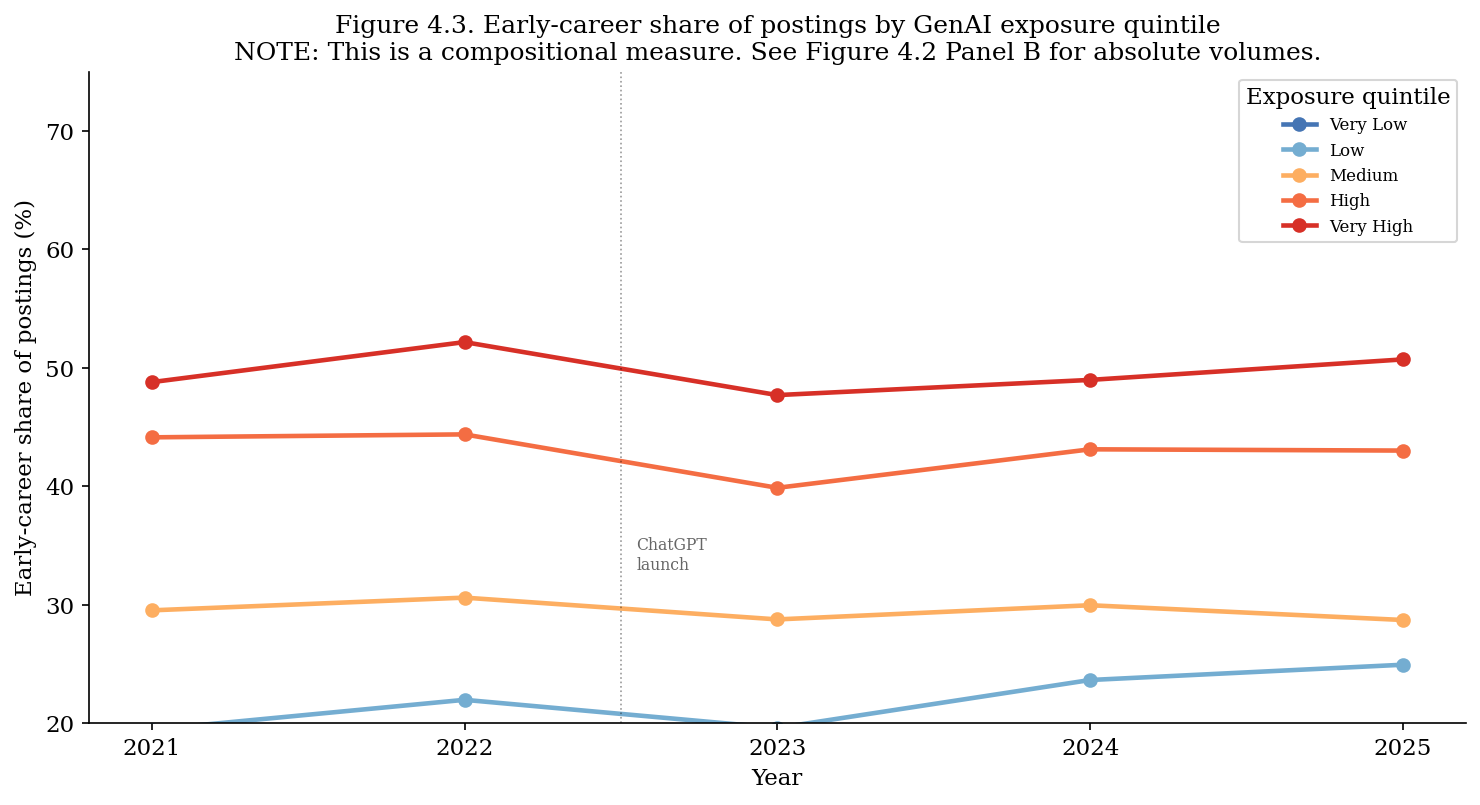

Saved: fig43_early_share.png


In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for q, c in zip(QUINTILE_ORDER, QUINTILE_COLORS):
    ax.plot(early_share_by_quintile.index, early_share_by_quintile[q]*100,
            marker='o', color=c, linewidth=2.2, label=q)

ax.axvline(2022.5, linestyle=':', color='black', linewidth=0.8, alpha=0.4)
ax.text(2022.55, 33, 'ChatGPT\nlaunch', fontsize=7.5, color='black', alpha=0.6)
ax.set_xlabel('Year')
ax.set_ylabel('Early-career share of postings (%)')
ax.set_title(
    'Figure 4.3. Early-career share of postings by GenAI exposure quintile\n'
    'NOTE: This is a compositional measure. See Figure 4.2 Panel B for absolute volumes.'
)
ax.set_xticks(early_share_by_quintile.index)
ax.legend(title='Exposure quintile', fontsize=8)
ax.set_ylim(20, 75)

plt.tight_layout()
plt.savefig('fig43_early_share.png', bbox_inches='tight')
plt.show()
print('Saved: fig43_early_share.png') 

---
## CELL 12 — FIGURE 4: Growth decomposition bar chart
> **CORRECTION 4: now shows BOTH share change AND absolute EC volume change**
> Mirrors Brynjolfsson et al. (2025) Figure A5, with additional panel

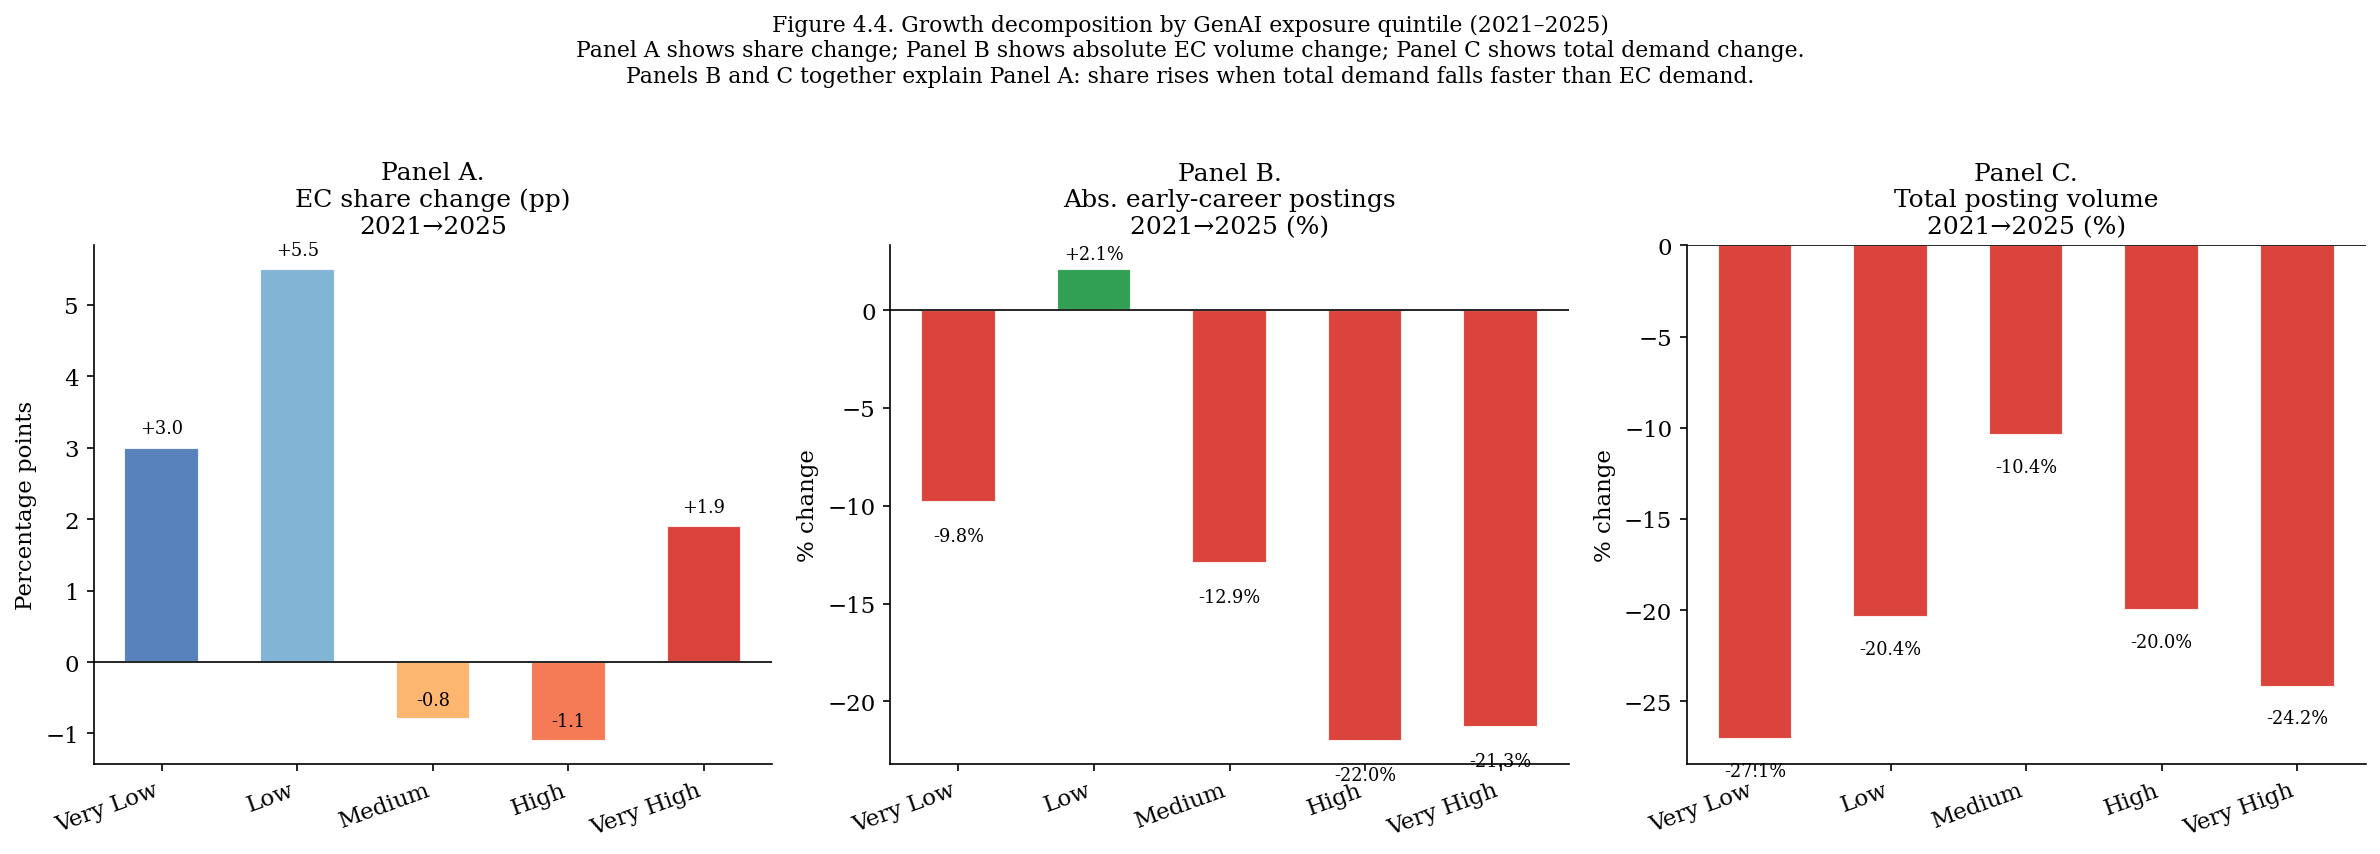

Saved: fig44_growth_decomposition.png


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
x = np.arange(len(QUINTILE_ORDER))
w = 0.55

# Panel A — EC share change (pp)
ax = axes[0]
vals_a = growth_table['Share change (pp)']
bars = ax.bar(x, vals_a, width=w, color=QUINTILE_COLORS, edgecolor='white', alpha=0.9)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(QUINTILE_ORDER, rotation=20, ha='right')
ax.set_ylabel('Percentage points')
ax.set_title('Panel A.\nEC share change (pp)\n2021→2025')
for bar, v in zip(bars, vals_a):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.2, f'{v:+.1f}', ha='center', fontsize=8.5)

# Panel B — Absolute EC postings change (%)
ax = axes[1]
vals_b = growth_table['Abs. EC postings change (%)']
colors_b = ['#d73027' if v < 0 else '#1a9641' for v in vals_b]
bars2 = ax.bar(x, vals_b, width=w, color=colors_b, edgecolor='white', alpha=0.9)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(QUINTILE_ORDER, rotation=20, ha='right')
ax.set_ylabel('% change')
ax.set_title('Panel B.\nAbs. early-career postings\n2021→2025 (%)')
for bar, v in zip(bars2, vals_b):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+(0.5 if v>=0 else -2.0),
            f'{v:+.1f}%', ha='center', fontsize=8.5)

# Panel C — Total demand change (%)
ax = axes[2]
vals_c = growth_table['Total demand change (%)']
colors_c = ['#d73027' if v < 0 else '#1a9641' for v in vals_c]
bars3 = ax.bar(x, vals_c, width=w, color=colors_c, edgecolor='white', alpha=0.9)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(QUINTILE_ORDER, rotation=20, ha='right')
ax.set_ylabel('% change')
ax.set_title('Panel C.\nTotal posting volume\n2021→2025 (%)')
for bar, v in zip(bars3, vals_c):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+(0.5 if v>=0 else -2.0),
            f'{v:+.1f}%', ha='center', fontsize=8.5)

fig.suptitle(
    'Figure 4.4. Growth decomposition by GenAI exposure quintile (2021–2025)\n'
    'Panel A shows share change; Panel B shows absolute EC volume change; Panel C shows total demand change.\n'
    'Panels B and C together explain Panel A: share rises when total demand falls faster than EC demand.',
    fontsize=10.5, y=1.03
)
plt.tight_layout()
plt.savefig('fig44_growth_decomposition.png', bbox_inches='tight')
plt.show()
print('Saved: fig44_growth_decomposition.png')

---
## CELL 13 — FIGURE 5: Heatmap of early-career share

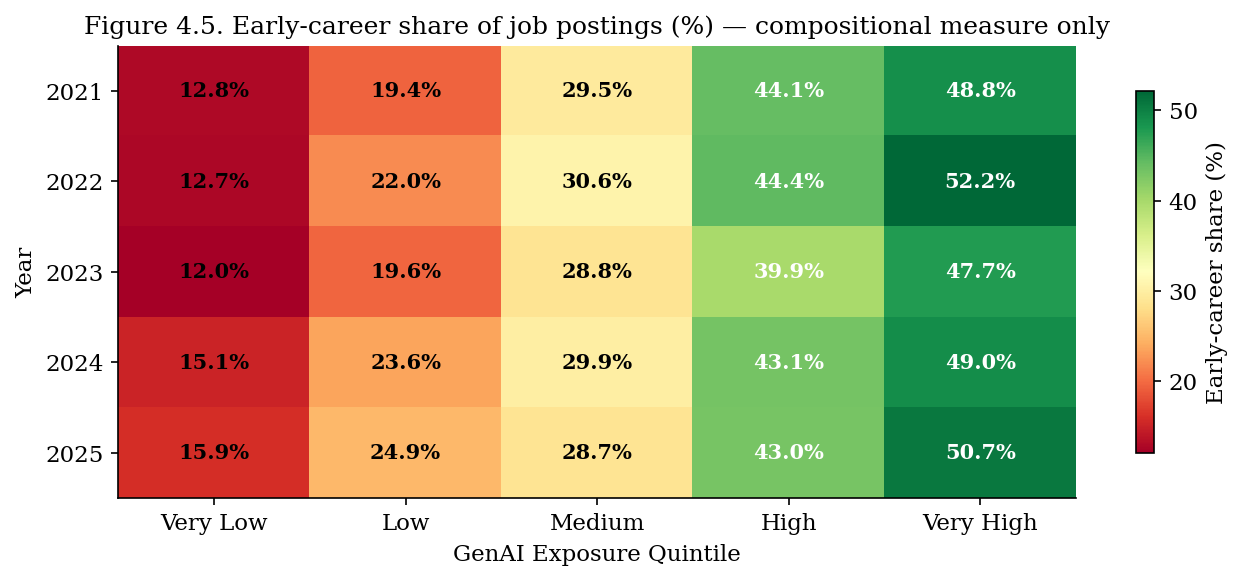

Saved: fig45_heatmap.png


In [14]:
heat_data = early_share_by_quintile * 100
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(heat_data.values, cmap='RdYlGn', aspect='auto',
               vmin=heat_data.values.min(), vmax=heat_data.values.max())
ax.set_xticks(range(len(QUINTILE_ORDER)))
ax.set_xticklabels(QUINTILE_ORDER)
ax.set_yticks(range(len(heat_data.index)))
ax.set_yticklabels(heat_data.index)
ax.set_xlabel('GenAI Exposure Quintile')
ax.set_ylabel('Year')
ax.set_title('Figure 4.5. Early-career share of job postings (%) — compositional measure only')
for i in range(len(heat_data.index)):
    for j in range(len(QUINTILE_ORDER)):
        val = heat_data.iloc[i, j]
        ax.text(j, i, f'{val:.1f}%', ha='center', va='center', fontsize=10,
                fontweight='bold',
                color='white' if val > heat_data.values.mean()+4 else 'black')
plt.colorbar(im, ax=ax, label='Early-career share (%)', shrink=0.8)
plt.tight_layout()
plt.savefig('fig45_heatmap.png', bbox_inches='tight')
plt.show()
print('Saved: fig45_heatmap.png')

---
## CELL 14 — REGRESSION ANALYSIS
> **CORRECTION 5: regression now formally tests post-2022 interaction**
> Chapter 4 Table 4.6

In [15]:
# ── Build regression dataset ─────────────────────────────────────────────────
reg_df = (
    df.groupby(['year','exposure_quintile'])
      .agg(
          early_share    = ('early_career', 'mean'),
          total_postings = ('job_id', 'count'),
          early_postings = ('early_career', 'sum'),
      ).reset_index()
)
reg_df['exposure_quintile'] = pd.Categorical(
    reg_df['exposure_quintile'], categories=QUINTILE_ORDER, ordered=True
)
# Post-2022 indicator (ChatGPT launched Nov 2022)
reg_df['post2022']  = (reg_df['year'] >= 2023).astype(int)
# Numeric quintile (1 = Very Low … 5 = Very High)
q_map = {q: i+1 for i,q in enumerate(QUINTILE_ORDER)}
reg_df['q_numeric'] = reg_df['exposure_quintile'].map(q_map)

print('Regression dataset (N =', len(reg_df), '):')
print(reg_df.to_string(index=False))

Regression dataset (N = 25 ):
 year exposure_quintile  early_share  total_postings  early_postings  post2022 q_numeric
 2021          Very Low     0.128284          226006           28993         0         1
 2021               Low     0.194465          182984           35584         0         2
 2021            Medium     0.295173          103739           30621         0         3
 2021              High     0.441234          118087           52104         0         4
 2021         Very High     0.487821           98817           48205         0         5
 2022          Very Low     0.127201          377066           47963         0         1
 2022               Low     0.219634          250421           55001         0         2
 2022            Medium     0.305918          145830           44612         0         3
 2022              High     0.443732          169429           75181         0         4
 2022         Very High     0.521644          128814           67195         0  

In [16]:
# ── Non-parametric tests ──────────────────────────────────────────────────────
print('=== Kruskal-Wallis test (posting-level): EC flag ~ exposure quintile ===')
groups = [df[df['exposure_quintile']==q]['early_career'].values for q in QUINTILE_ORDER]
kw_stat, kw_p = stats.kruskal(*groups)
print(f'H = {kw_stat:.1f}, p = {kw_p:.2e}')

print('\n=== Spearman rank correlation: quintile rank vs EC share (by year) ===')
for yr in sorted(df['year'].unique()):
    yr_means = (
        df[df['year']==yr].groupby('exposure_quintile')['early_career']
          .mean().reindex(QUINTILE_ORDER)
    )
    rho, p = stats.spearmanr([1,2,3,4,5], yr_means.values)
    sig = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'n.s.'))
    print(f'  {yr}: rho={rho:+.3f}, p={p:.4f}  {sig}')

=== Kruskal-Wallis test (posting-level): EC flag ~ exposure quintile ===
H = 322507.2, p = 0.00e+00

=== Spearman rank correlation: quintile rank vs EC share (by year) ===
  2021: rho=+1.000, p=0.0000  ***
  2022: rho=+1.000, p=0.0000  ***
  2023: rho=+1.000, p=0.0000  ***
  2024: rho=+1.000, p=0.0000  ***
  2025: rho=+1.000, p=0.0000  ***


In [17]:
# ── Model 1: Quintile dummies + year FE ──────────────────────────────────────
model1 = smf.ols(
    'early_share ~ C(exposure_quintile, Treatment("Very Low")) + C(year)',
    data=reg_df
).fit(cov_type='HC3')

print('=== MODEL 1: Early-career share ~ Quintile dummies + Year FE ===')
print(f'R²={model1.rsquared:.3f}  Adj.R²={model1.rsquared_adj:.3f}  N={int(model1.nobs)}')
c1 = pd.DataFrame({'Coef': model1.params, 'SE': model1.bse,
                    't': model1.tvalues, 'p': model1.pvalues}).round(4)
c1['Sig.'] = c1['p'].apply(lambda p: '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else '')))
print(c1.to_string())

with open('model1_summary.txt', 'w') as f:
    f.write(model1.summary().as_text())

=== MODEL 1: Early-career share ~ Quintile dummies + Year FE ===
R²=0.993  Adj.R²=0.990  N=25
                                                            Coef      SE        t       p Sig.
Intercept                                                 0.1312  0.0093  14.0510  0.0000  ***
C(exposure_quintile, Treatment("Very Low"))[T.Low]        0.0820  0.0118   6.9369  0.0000  ***
C(exposure_quintile, Treatment("Very Low"))[T.Medium]     0.1579  0.0102  15.4160  0.0000  ***
C(exposure_quintile, Treatment("Very Low"))[T.High]       0.2918  0.0105  27.7981  0.0000  ***
C(exposure_quintile, Treatment("Very Low"))[T.Very High]  0.3594  0.0098  36.7114  0.0000  ***
C(year)[T.2022]                                           0.0142  0.0119   1.1921  0.2332     
C(year)[T.2023]                                          -0.0135  0.0100  -1.3558  0.1752     
C(year)[T.2024]                                           0.0122  0.0104   1.1712  0.2415     
C(year)[T.2025]                                    

In [18]:
# ── Model 2: Continuous quintile × post-2022 interaction ──────────────────────
model2 = smf.ols(
    'early_share ~ q_numeric * post2022 + C(year)',
    data=reg_df
).fit(cov_type='HC3')

print('=== MODEL 2: Quintile rank × Post-2022 interaction ===')
print(f'R²={model2.rsquared:.3f}  Adj.R²={model2.rsquared_adj:.3f}  N={int(model2.nobs)}')
c2 = pd.DataFrame({'Coef': model2.params, 'SE': model2.bse,
                    't': model2.tvalues, 'p': model2.pvalues}).round(4)
c2['Sig.'] = c2['p'].apply(lambda p: '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else '')))
print(c2.to_string())

# Interpret interaction
inter = model2.params.get('q_numeric:post2022', None)
inter_p = model2.pvalues.get('q_numeric:post2022', None)
if inter is not None:
    print(f'\nInteraction: each quintile step = {inter*100:.2f} pp additional EC share '
          f'in post-2022 period (p={inter_p:.4f})')
    print('NOTE: This is a COMPOSITIONAL finding. Absolute EC volumes declined simultaneously.')

with open('model2_summary.txt', 'w') as f:
    f.write(model2.summary().as_text())

=== MODEL 2: Quintile rank × Post-2022 interaction ===
R²=0.997  Adj.R²=0.994  N=25
                           Coef      SE        t       p Sig.
Intercept                0.1206  0.0145   8.3052  0.0000  ***
q_numeric[T.2]           0.0793  0.0166   4.7677  0.0000  ***
q_numeric[T.3]           0.1728  0.0139  12.4483  0.0000  ***
q_numeric[T.4]           0.3147  0.0171  18.4584  0.0000  ***
q_numeric[T.5]           0.3770  0.0220  17.1517  0.0000  ***
C(year)[T.2022]          0.0142  0.0105   1.3508  0.1768     
C(year)[T.2023]         -0.0130  0.0070  -1.8620  0.0626     
C(year)[T.2024]          0.0127  0.0056   2.2533  0.0242    *
C(year)[T.2025]          0.0175  0.0069   2.5508  0.0107    *
post2022                 0.0171  0.0112   1.5292  0.1262     
q_numeric[T.2]:post2022  0.0044  0.0198   0.2221  0.8243     
q_numeric[T.3]:post2022 -0.0249  0.0198  -1.2559  0.2092     
q_numeric[T.4]:post2022 -0.0383  0.0177  -2.1620  0.0306    *
q_numeric[T.5]:post2022 -0.0292  0.0232  -1.2615

---
## CELL 15 — FIGURE 6: Regression coefficient plot
> Chapter 4 Figure 4.6 — mirrors Brynjolfsson et al. (2025) Figure 4

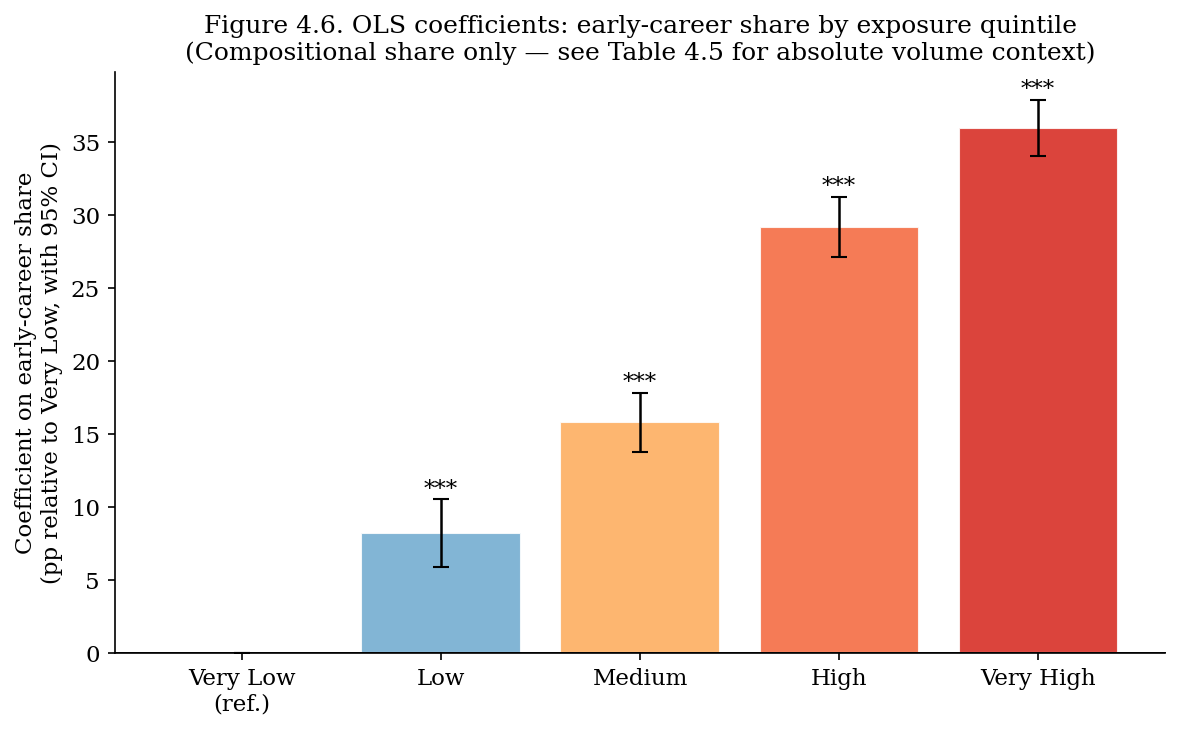

Saved: fig46_regression_coefs.png


In [19]:
coefs, errors, labels = [0], [0], ['Very Low\n(ref.)']
for q in QUINTILE_ORDER[1:]:
    key = f'C(exposure_quintile, Treatment("Very Low"))[T.{q}]'
    if key in model1.params:
        coefs.append(model1.params[key])
        errors.append(model1.bse[key] * 1.96)
        labels.append(q)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(labels))
ax.bar(x, [c*100 for c in coefs], color=QUINTILE_COLORS, edgecolor='white', alpha=0.9,
       yerr=[e*100 for e in errors], capsize=4, error_kw={'linewidth': 1.2})
ax.axhline(0, color='black', linewidth=0.9)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Coefficient on early-career share\n(pp relative to Very Low, with 95% CI)')
ax.set_title(
    'Figure 4.6. OLS coefficients: early-career share by exposure quintile\n'
    '(Compositional share only — see Table 4.5 for absolute volume context)'
)

for i, (c, e) in enumerate(zip(coefs, errors)):
    if i == 0: continue
    key = f'C(exposure_quintile, Treatment("Very Low"))[T.{QUINTILE_ORDER[i]}]'
    p = model1.pvalues.get(key, 1)
    star = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else ''))
    ax.text(i, (c+abs(e))*100+0.3, star, ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('fig46_regression_coefs.png', bbox_inches='tight')
plt.show()
print('Saved: fig46_regression_coefs.png')

---
## CELL 16 — Save all outputs & final summary

In [20]:
print('=== ALL OUTPUTS SAVED ===')
print()
print('CSV tables:')
for f in ['table41_occupation_exposure.csv','table42_total_demand.csv',
          'table43_early_career_absolute.csv','table44_early_career_share.csv',
          'table45_growth_decomposition.csv','share_by_quintile.csv',
          'model1_summary.txt','model2_summary.txt']:
    print(f'  {f}')
print()
print('Figures (PNG):')
for f in ['fig41_rq1_exposure_bar.png','fig42_indexed_demand.png',
          'fig43_early_share.png','fig44_growth_decomposition.png',
          'fig45_heatmap.png','fig46_regression_coefs.png']:
    print(f'  {f}')
print()
print('=== FINAL DATASET SUMMARY ===')
print(f'Total postings: {len(df):,}')
print(f'Occupations: {occupation_exposure.shape[0]:,}')
print(f'Years: {sorted(df["year"].unique())}')
print(f'Overall early-career share: {df["early_career"].mean()*100:.1f}%')
print()
print('=== CORRECTIONS APPLIED ===')
print('1. Absolute EC postings table added (Table 4.3)')
print('2. Growth decomposition includes both share AND volume change (Table 4.5)')
print('3. Share-vs-volume divergence explicitly flagged in regression output')
print('4. Swedish early-career keywords documented in Cell 1')
print('5. Figure 4.4 now has 3 panels (share, EC volume, total demand)')
print('6. Figure 4.6 title flags compositional-only caveat')

=== ALL OUTPUTS SAVED ===

CSV tables:
  table41_occupation_exposure.csv
  table42_total_demand.csv
  table43_early_career_absolute.csv
  table44_early_career_share.csv
  table45_growth_decomposition.csv
  share_by_quintile.csv
  model1_summary.txt
  model2_summary.txt

Figures (PNG):
  fig41_rq1_exposure_bar.png
  fig42_indexed_demand.png
  fig43_early_share.png
  fig44_growth_decomposition.png
  fig45_heatmap.png
  fig46_regression_coefs.png

=== FINAL DATASET SUMMARY ===
Total postings: 3,613,228
Occupations: 1,938
Years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Overall early-career share: 27.0%

=== CORRECTIONS APPLIED ===
1. Absolute EC postings table added (Table 4.3)
2. Growth decomposition includes both share AND volume change (Table 4.5)
3. Share-vs-volume divergence explicitly flagged in regression output
4. Swedish early-career keywords documented in Cell 1
5. Figure 4.4 now has 3 panels (share, EC volume, total demand)
6. Figure 4.6 t